## Przykład modelu klasyfikacyjnego krok po kroku 

### Opis pliku `titanic_agh.csv`

Plik `titanic_pl.csv` zawiera dane dotyczące pasażerów Titanica. Dane te mogą być wykorzystane do analizy przeżywalności w zależności od różnych cech pasażerów.

## Struktura danych

| Kolumna                  | Opis                                                                 |
|--------------------------|----------------------------------------------------------------------|
| `ID_pasażera`            | Unikalny identyfikator pasażera                                     |
| `Przeżył`                | Informacja o przeżyciu: `1` – przeżył, `0` – nie przeżył             |
| `Klasa`                  | Klasa biletu: `1` – pierwsza, `2` – druga, `3` – trzecia             |
| `Płeć`                   | Płeć pasażera (`male`, `female`)                                     |
| `Wiek`                   | Wiek pasażera w latach         |
| `Cena_biletu`            | Cena biletu w funtach sterlingach                                    |
| `Port_zaokrętowania`     | Port, z którego pasażer wsiadł: `C` – Cherbourg, `Q` – Queenstown, `S` – Southampton |


### Import wymaganych (wybranych) bibliotek

In [20]:
# Importujemy biblioteki do obróbki danych, wizualizacji i budowy modeli
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# wyłączenie ostrzeżeń (opcjonalnie)
import warnings
warnings.filterwarnings("ignore")

# wartość początkowa dla generatora liczb losowych
seed=42

In [21]:
#Dodatkowe "ułatwienia" w ustawieniach wyświetlania

# Wyłączenie ramki wyświetlania (jeśli nam przeszkadza)
from IPython.display import display, HTML
display(HTML("<style>.output_scroll { height: auto !important; }</style>"))

### Wczytanie pliku danych

In [22]:
# Wczytaj plik (upewnij się, że plik jest w tym samym folderze co twój skrypt lub podaj pełną ścieżkę)
titanic_df = pd.read_csv("C:\\Users\\XYZ\\OneDrive\\Pulpit\\projects\\projects_learning_AGH\\data_AGH\\titanic_agh.csv")

### Zrozumienie danych

In [23]:
# Jaka jest liczba przypadków? Jaka jest liczba zmiennych? Jak wygląda zbiór danych?
display(titanic_df)

,ID_pasażera,Przeżył,Klasa,Płeć,Wiek,Cena_biletu,Port_zaokrętowania
0,1,0,3,male,22.0,7.2500,S
1,2,1,1,female,38.0,71.2833,C
2,3,1,3,female,26.0,7.9250,S
3,4,1,1,female,35.0,53.1000,S
4,5,0,3,male,35.0,8.0500,S
...,...,...,...,...,...,...,...
709,886,0,3,female,39.0,29.1250,Q
710,887,0,2,male,27.0,13.0000,S
711,888,1,1,female,19.0,30.0000,S
712,890,1,1,male,26.0,30.0000,C


In [24]:
# Podstawowe sprawdzenie typów danych
titanic_df.dtypes

ID_pasażera             int64
Przeżył                 int64
Klasa                   int64
Płeć                      str
Wiek                  float64
Cena_biletu           float64
Port_zaokrętowania        str
dtype: object

In [25]:
# Zamieniamy typ zmiennej 'Płeć' oraz zmiennej 'Port_zaokrętowania'
titanic_df["Płeć"] = titanic_df["Płeć"].astype("category")
titanic_df["Port_zaokrętowania"] = titanic_df["Port_zaokrętowania"].astype("category")

In [26]:
# Podstawowe sprawdzenie typów danych
titanic_df.dtypes

ID_pasażera              int64
Przeżył                  int64
Klasa                    int64
Płeć                  category
Wiek                   float64
Cena_biletu            float64
Port_zaokrętowania    category
dtype: object

In [27]:
# Sprawdzenie liczby unikalnych wartości
titanic_df.nunique()

ID_pasażera           714
Przeżył                 2
Klasa                   3
Płeć                    2
Wiek                   88
Cena_biletu           220
Port_zaokrętowania      3
dtype: int64

### Ważna decyzja - rola zmiennych w analizie - tworzymy zazwyczaj większą liczbę list na różnym poziomie szczegółowości

In [28]:
# Określ rolę zmiennych w analizie
# Wszystkie zmienne
additional =['ID_pasażera']
variables = [var for var in titanic_df.columns if var not in additional]

# Podział na rolę w analizie
dependent = ['Przeżył']
predictors = [var for var in variables if var not in dependent]

# Podział wg skali pomiarowej
cat_pred = ['Płeć', 'Port_zaokrętowania', 'Klasa']
num_pred = [var for var in predictors if var not in cat_pred]

# wyświetl predyktory ilosciowe
display(num_pred)

['Wiek', 'Cena_biletu']

### 💡 Zmienna `Klasa` ilościowa czy ilościowa?

Zmienna `Klasa` (1, 2, 3) jest zmienną jakościową z natury (reprezentuje klasy pasażerów), często traktujemy ją jednak **jak zmienną ilościową**, ponieważ:

- Wartości `1`, `2`, `3` mają **naturalny porządek** (pierwsza klasa > druga > trzecia),
- Istnieje **hierarchia komfortu, ceny biletu, dostępu do szalup ratunkowych** itd.,
- W modelach uczenia maszynowego możemy ją wykorzystać bez kodowania (jako liczby całkowite),
- Traktowanie jej jako liczby ułatwia wizualizację i korelację z innymi zmiennymi liczbowymi.

📌 **Uwaga:** Jeśli chcemy dokładniej oddać strukturę danych, można też zastosować kodowanie `one-hot`, które nie zakłada relacji porządkowej.

### Ocena jakości zbioru danych

1. Raport braków danych
2. Analiza rozkładów zmienne ilościowe - histogramy, wykres ramkowy, statystyki
3. Analiza rozkładów zmienne jakościowe - histogramy, tabela liczności
4. Ocena pod kątem wartości odstających i kategorii o małej liczności

In [29]:
# Sprawdzenie brakujących danych
titanic_df[variables].isnull().sum()

Przeżył               0
Klasa                 0
Płeć                  0
Wiek                  0
Cena_biletu           0
Port_zaokrętowania    2
dtype: int64

### Tym razem nie będziemy umieszczać skomplikowanych funkcji w kodzie notatnika, aby nie zaciemniać obrazu. Skorzystamy z pliku zewnętrzego, który zaimportujemy jako osobną bibliotekę.

In [30]:
import sys
import os

# Dodaje katalog nadrzędny (poziom wyżej) do ścieżek Pythona
sys.path.append(os.path.abspath(".."))

# Jeśli to nie wystarczy, możesz dodać katalog dwa poziomy wyżej:
sys.path.append(os.path.abspath("../.."))

import projects_learning_AGH.data_AGH.analysis_general_helpers as agh


### 🧰 Korzystanie z własnych funkcji w osobnym pliku – co się tu właściwie dzieje?

W ramach organizacji naszego projektu postanowiliśmy stworzyć osobny plik z funkcjami pomocniczymi:

```plaintext
analysis_general_helpers.py


📌 **Dlaczego warto przenieść funkcje do osobnego pliku?**

- **Porządek w kodzie** – zamiast mieć wszystkie funkcje w jednym notatniku, trzymamy je w dedykowanym pliku.
- **Wielokrotne użycie** – możemy używać tych funkcji w wielu notatnikach lub projektach bez kopiowania kodu.
- **Łatwiejsze testowanie i modyfikacja** – funkcje są odseparowane od głównego kodu analitycznego, więc łatwiej je rozwijać i poprawiać.

📦 **W pliku `analysis_general_helpers.py` umieszczamy np.:**

- funkcje do tworzenia zmiennych pochodnych,
- funkcje do imputacji braków danych,
- funkcje do wizualizacji lub oceny modeli.

🧠 **Importowanie do notatnika:**  
Po zapisaniu pliku w tym samym folderze co notatnik, możemy z niego korzystać tak jak z biblioteki:

import analysis_general_helpers as agh

📌 W tym miejscu wywołujemy funkcję `plot_categorical_bars` z naszej własnej biblioteki `analysis_general_helpers.py`, którą wcześniej zaimportowaliśmy jako `agh`.

Dzięki temu, że zapisaliśmy funkcję w osobnym pliku `.py`, możemy teraz użyć jej w notatniku tak samo, jak używamy funkcji z wbudowanych bibliotek Pythona.

Wywołanie:

```python
agh.plot_categorical_bars(titanic_df, dependent)


#### W stuacji, gdy zmieniamy kod w bibliotece i chcemy, aby zmiany były widoczne z poziomu notatnika, wywołujemy poniższy kod: 

In [31]:

import importlib

# 1. Dodaj ścieżkę do folderu, w którym faktycznie leży plik
sys.path.append(os.path.abspath("projects_learning_AGH/data_AGH"))

# 2. Jeśli notatnik jest w podfolderze, przeszukaj też katalogi wyżej:
sys.path.append(os.path.abspath("../projects_learning_AGH/data_AGH"))
sys.path.append(os.path.abspath("../../projects_learning_AGH/data_AGH"))

# 3. Teraz import zadziała
import analysis_general_helpers as agh
importlib.reload(agh)

<module 'analysis_general_helpers' from 'c:\\Users\\XYZ\\OneDrive\\Pulpit\\projects\\projects_learning_AGH\\data_AGH\\analysis_general_helpers.py'>

### Zaczynamy od rozkładu zmiennej zależnej

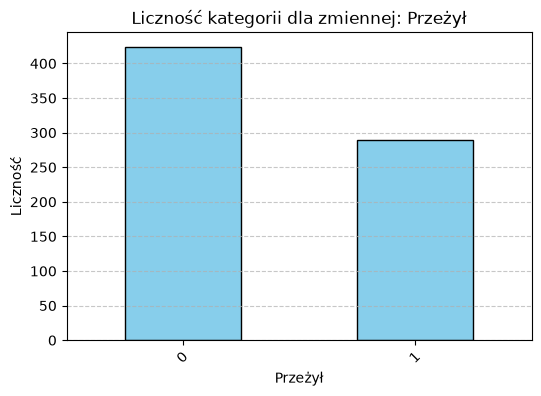

In [32]:
# Rozkład zmiennej zależnej
agh.plot_categorical_bars(titanic_df,dependent)

### W kolejnym kroku na tapet bierzemy predyktory

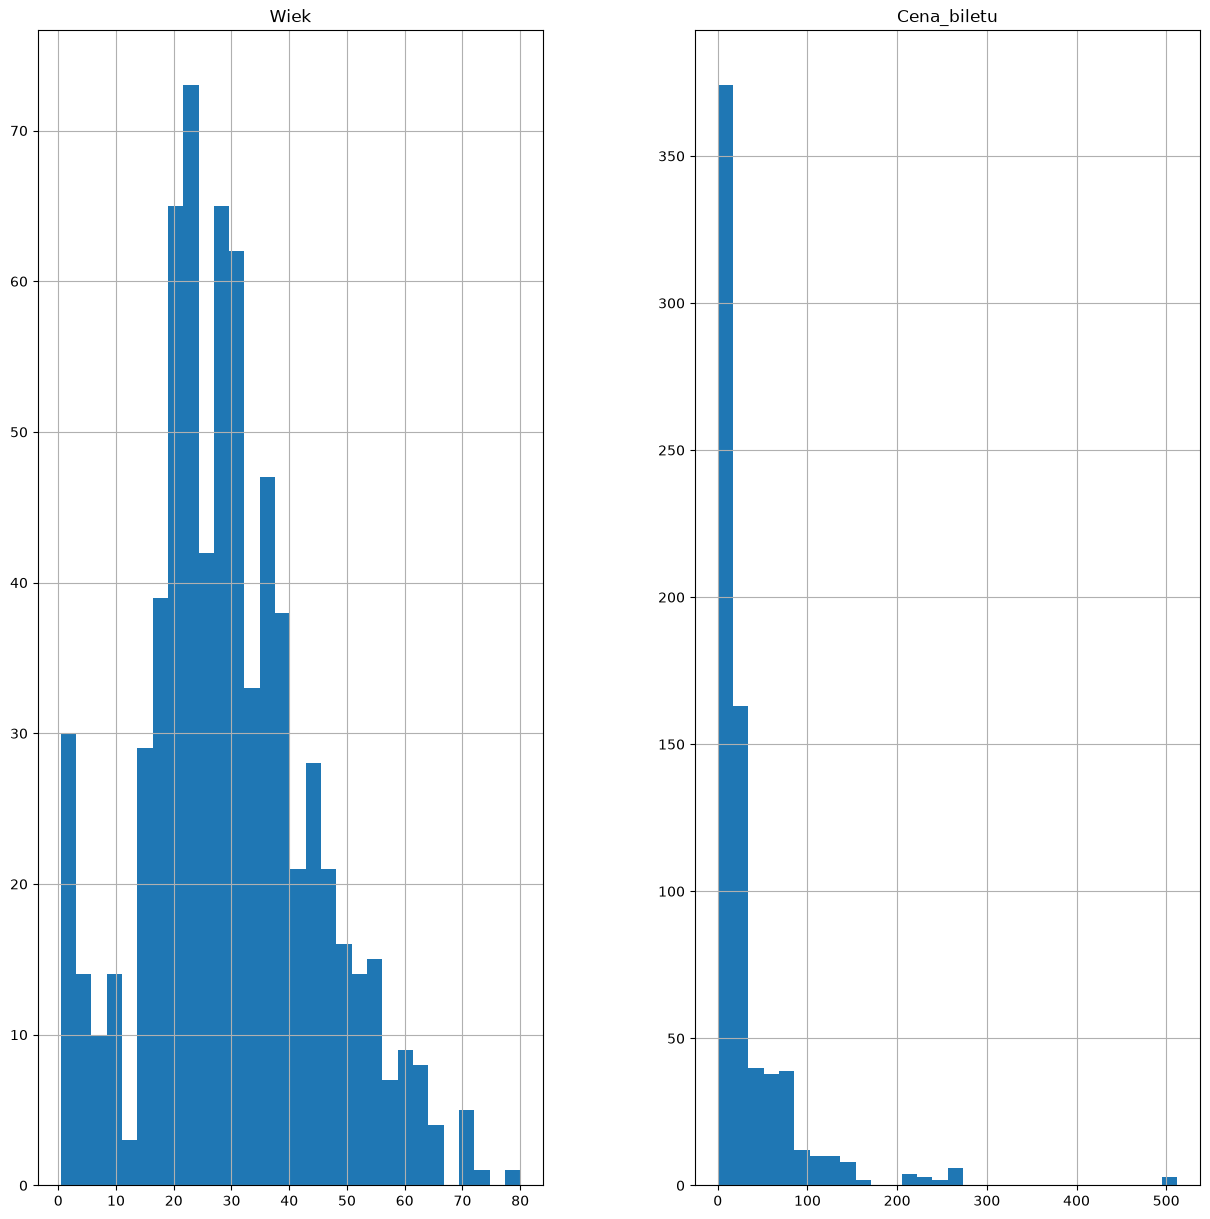

In [33]:
titanic_df[num_pred].hist(bins=30, figsize=(15,15))
plt.show()

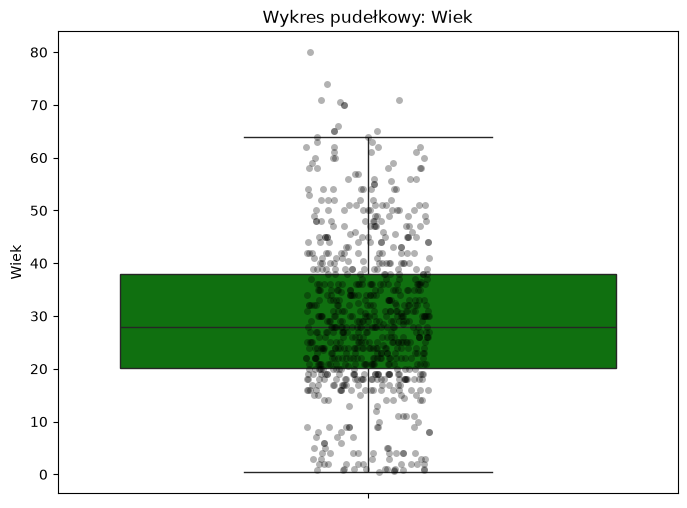

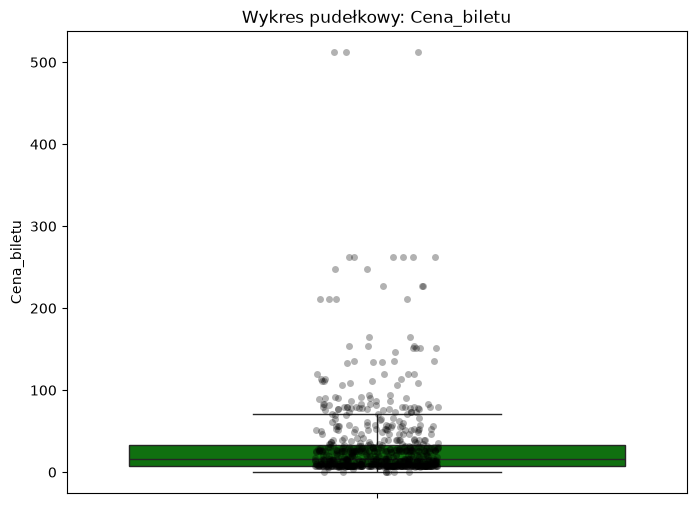

In [34]:
# Wykres pudełkowy
agh.plot_box_strip(titanic_df,num_pred)

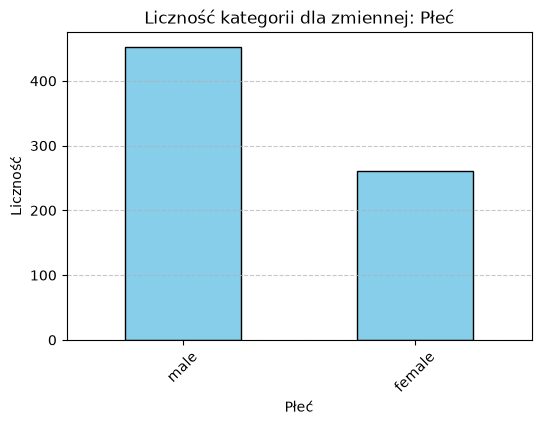

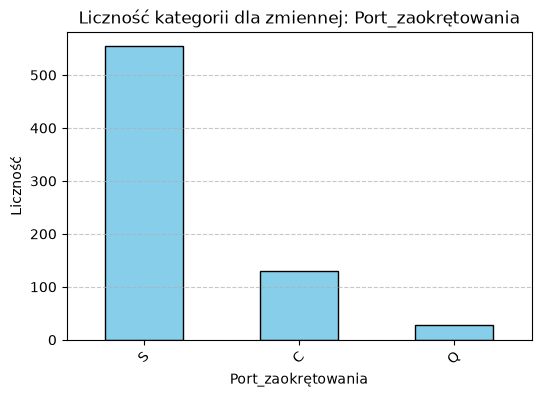

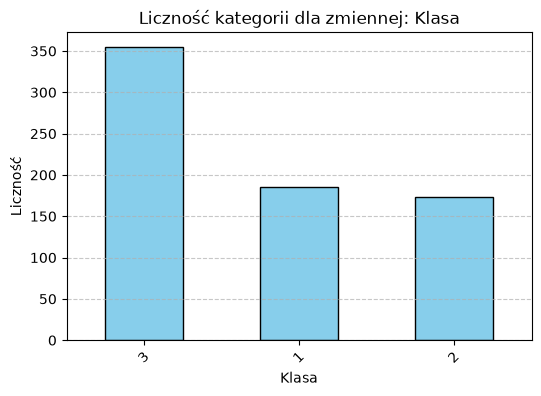

In [35]:
# Rozkład predyktorów jakościowych
agh.plot_categorical_bars(titanic_df,cat_pred)

#### W zadaniu regresyjnym relację pomiędzy zmienną zależną a predyktorami opisywialiśmy za pomocą macierzy korelacji, wykresów rozrzutu oraz ramkowych w grupach predyktorów jakościowych.

#### W przypadku modelu klasyfikacyjnego siłę powiązania ocenimy za pomocą miary IV Information Value a charakter powiązania za pomocą wykresu Weight of Evidence. 

In [36]:
iv_results = agh.calculate_iv_new(
    df=titanic_df,
    y='Przeżył',
    num_vars=num_pred,
    cat_vars=cat_pred
)

display(iv_results)

,zmienna,IV,siła_predykcyjna
0,Płeć,1.309197,bardzo silna / podejrzana
1,Cena_biletu,0.647945,bardzo silna / podejrzana
2,Klasa,0.565260,bardzo silna / podejrzana
3,Port_zaokrętowania,0.160990,średnia
4,Wiek,0.108693,średnia


### 🧠 Jak mierzymy siłę predykcyjną zmiennej?

Najczęściej stosowaną miarą jest **Information Value (IV)** – czyli **suma różnic między udziałami klas pomnożona przez WOE w każdej grupie (binie)** danej zmiennej.

#### 📐 Wzór:
Dla każdej grupy (bina):

IV = ∑ ( %good - %bad ) × WOE


- `%good` – udział klasy pozytywnej (np. `Przeżył = 1`) w danym binie,
- `%bad` – udział klasy negatywnej (np. `Przeżył = 0`) w tym samym binie,
- `WOE` – Weight of Evidence dla tego bina.

#### 📊 Interpretacja wartości IV:

| IV              | Siła predykcyjna zmiennej             |
|-----------------|----------------------------------------|
| < 0.02          | Brak wartości predykcyjnej             |
| 0.02 – 0.1      | Słaba                                  |
| 0.1 – 0.3       | Średnia                                |
| 0.3 – 0.5       | Silna                                  |
| > 0.5           | Bardzo silna (lub podejrzana – może wskazywać na target leakage) |

---

📌 **IV** pozwala:
- porównać zmienne między sobą pod kątem przydatności predykcyjnej,
- ustawić **filtr cech** przed budową modelu,
- wizualnie zrozumieć, gdzie występują różnice między klasami (przez WOE).

WOE i IV najlepiej działają dla zmiennych binarnych (`y = 0/1`) i są **szczególnie popularne w modelach scoringowych** (np. logit).


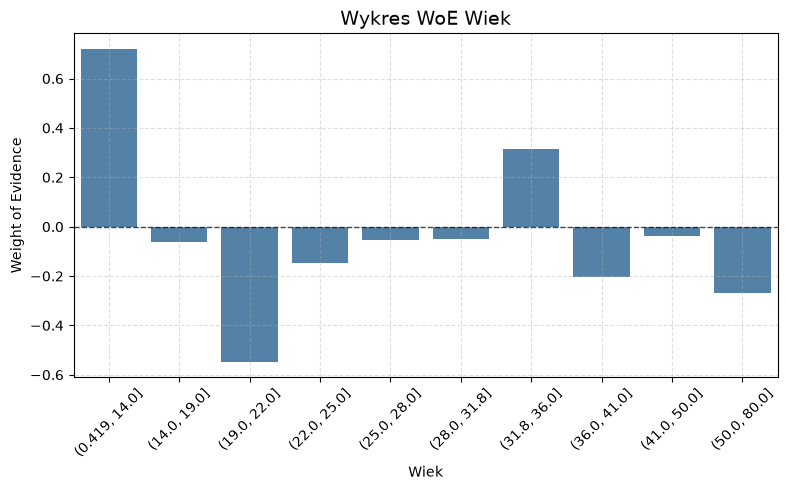

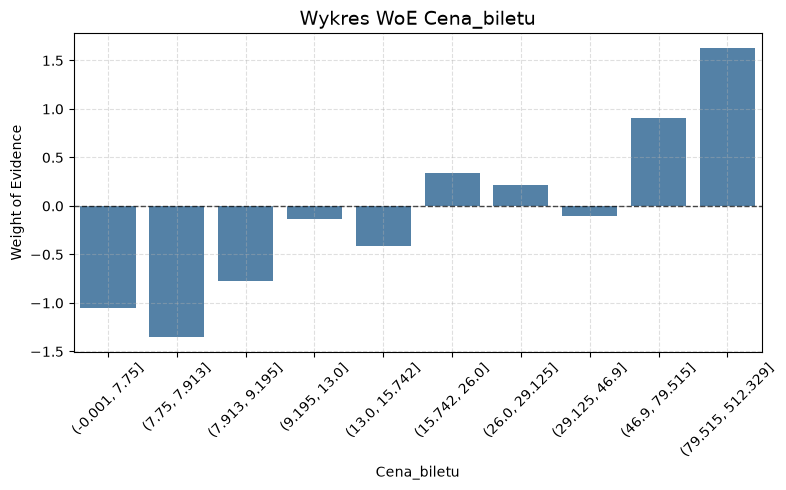

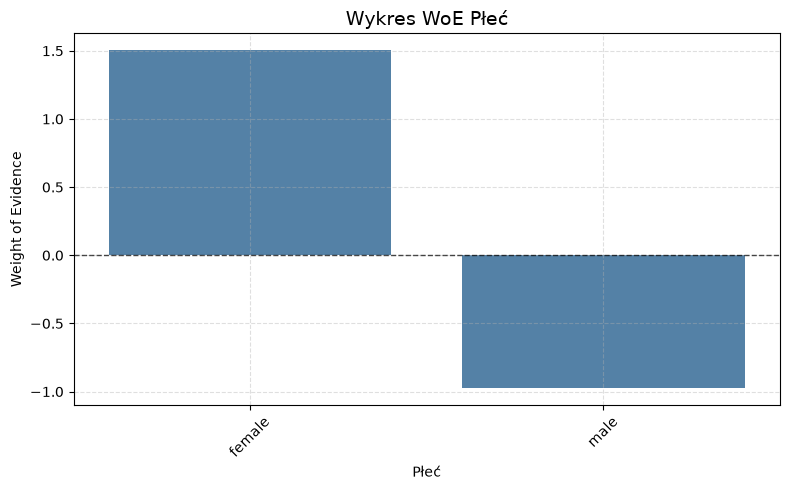

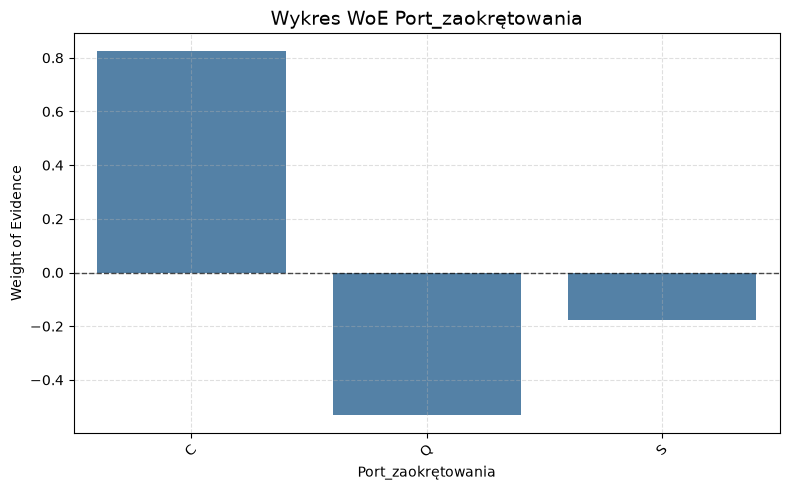

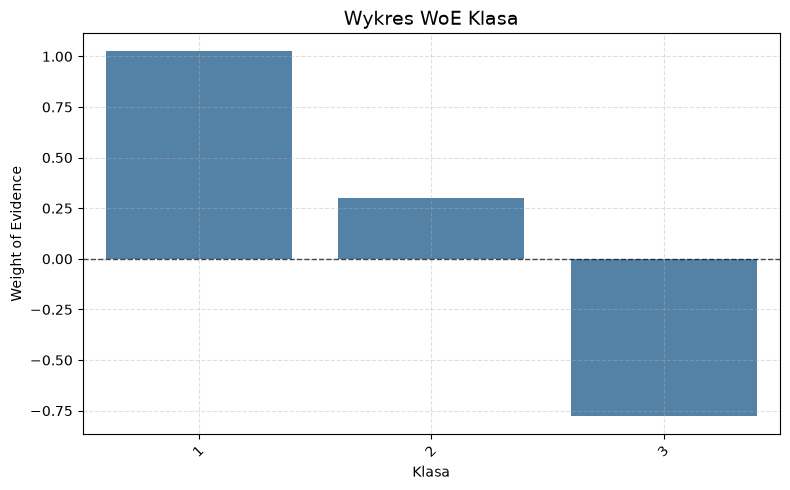

In [37]:
agh.plot_woe_charts(
    df=titanic_df,
    y='Przeżył',
    num_vars=num_pred,
    cat_vars=cat_pred,
    bad_class=0  # zakładamy, że 0 oznacza klasę "negatywną" (nie przeżył)
)

### Zrozumieliśmy dane teraz możemy je przygotować do analizy

#### Zaczynamy od podziału na zbiór uczący i testowy

In [38]:
from sklearn.model_selection import train_test_split

# Podział na zbiory X i y
X = titanic_df[variables].drop(columns='Przeżył')
y = titanic_df['Przeżył']

# 2. Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,     # 30% danych do testu
    random_state=42,   # dla powtarzalności
    stratify=y         # utrzymuje proporcje klas
)

### 🧠 Dlaczego `stratify=y`?

Ponieważ `Przeżył` to zmienna binarna (`0/1`), warto zadbać, by **proporcja klas była podobna w obu zbiorach** – to zapewnia **bardziej wiarygodną ocenę modelu**

### 🚢 Imputacja brakujących danych w zmiennej `Port_zaokrętowania`

Zmienna `Port_zaokrętowania` zawiera informację o miejscu, z którego pasażer wsiadł na pokład Titanica:
- `S` – Southampton
- `C` – Cherbourg
- `Q` – Queenstown

Kilka wpisów ma brakujące dane (`NaN`). Uzupełniamy je wartością **najczęściej występującą** (modą), ponieważ:
- Jest to prosta, szybka i popularna metoda imputacji zmiennych kategorycznych,
- Najczęstszy port (`S`) dominuje w zbiorze danych i jest najbardziej prawdopodobnym miejscem zaokrętowania dla osób z brakami.

In [39]:
# Importujemy klasę SimpleImputer z biblioteki sklearn, służy do uzupełniania braków danych
from sklearn.impute import SimpleImputer

# Tworzymy obiekt imputera, który uzupełnia braki najczęściej występującą wartością (modalną)
imputer = SimpleImputer(strategy='most_frequent')

# Dopasowujemy imputera do danych treningowych i jednocześnie uzupełniamy braki w kolumnie 'Port_zaokrętowania'
X_train[['Port_zaokrętowania']] = imputer.fit_transform(X_train[['Port_zaokrętowania']])

# Uzupełniamy braki w danych testowych na podstawie tego, czego nauczył się imputer na danych treningowych
X_test[['Port_zaokrętowania']] = imputer.transform(X_test[['Port_zaokrętowania']])

### 🚢 Przycinamy wartości zmiennych ilościowych

In [40]:
from feature_engine.outliers import Winsorizer # Wartosci odstające

# capping_method='iqr' - metoda oparta na rozstępie kwartylowym
# fold=1.5 - parametr sterujacy szerokocią przycinania 
# tail='both' → obcina wartości odstające zarówno z lewej (dolne wartości), jak i z prawej strony (górne wartości).

winsorizer = Winsorizer(capping_method='iqr', fold=1.5, tail='both')

# Dla danych treningowych: dopasowujemy transformację (winsoryzację) i ją stosujemy.
# 'fit_transform' oznacza: oblicz progi (np. percentyle) na podstawie danych treningowych
# i od razu przekształć dane, przycinając wartości odstające w kolumnach numerycznych.
X_train[num_pred] = winsorizer.fit_transform(X_train[num_pred])

# Dla danych testowych: stosujemy TYLKO przekształcenie, bez ponownego dopasowania.
# Używamy tych samych progów, co dla danych treningowych — zapewnia to spójność transformacji.
X_test[num_pred] = winsorizer.transform(X_test[num_pred])

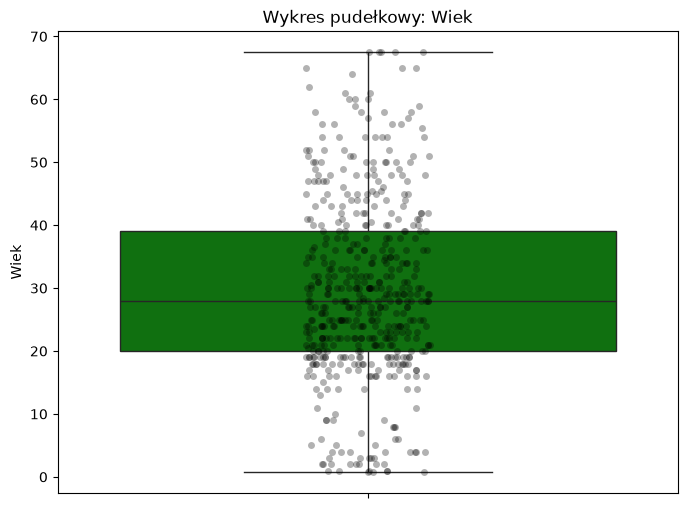

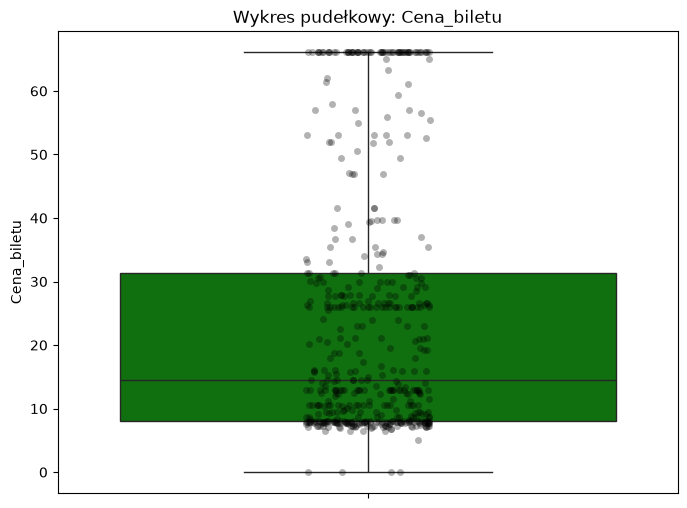

In [41]:
# Wykres pudełkowy
agh.plot_box_strip(X_train,num_pred)

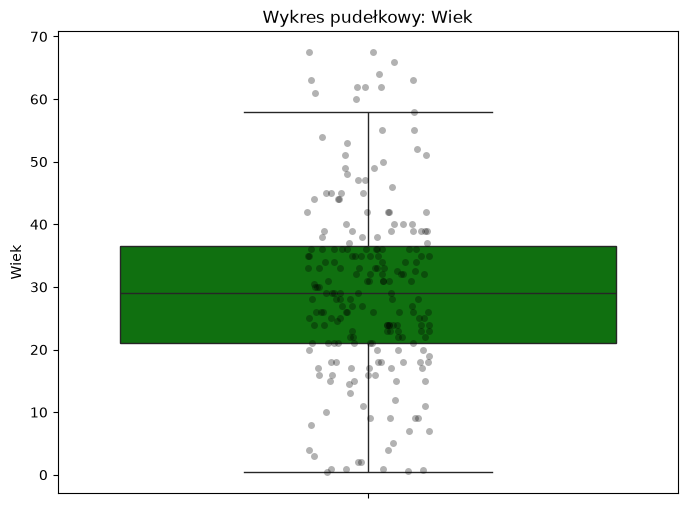

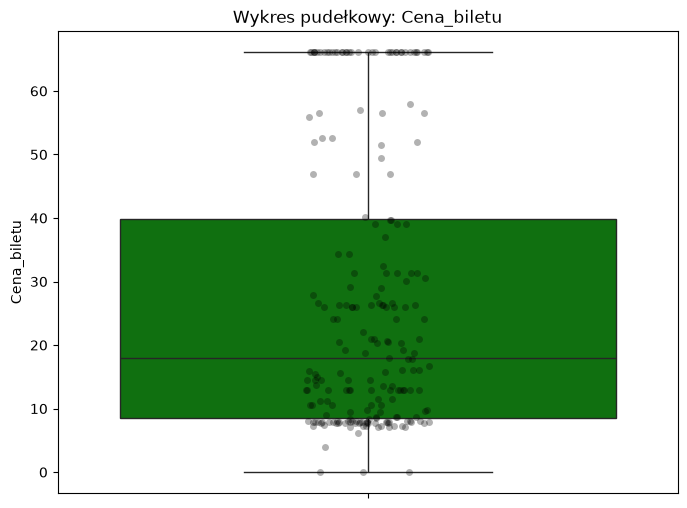

In [42]:
# Wykres pudełkowy
agh.plot_box_strip(X_test,num_pred)

### Teraz kodowanie zmiennych jakościowych - przećwiczymy dwa sposoby - one-hot oraz ordinal target based

In [43]:
from feature_engine.encoding import OrdinalEncoder

# Tworzymy encoder
encoder = OrdinalEncoder(variables=['Port_zaokrętowania'], encoding_method='ordered')

# Dopasowujemy encoder do danych treningowych
X_train = encoder.fit_transform(X_train, y_train)

# Transformujemy dane testowe
X_test = encoder.transform(X_test)

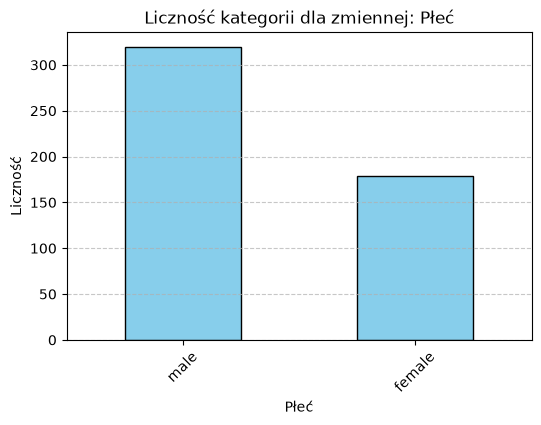

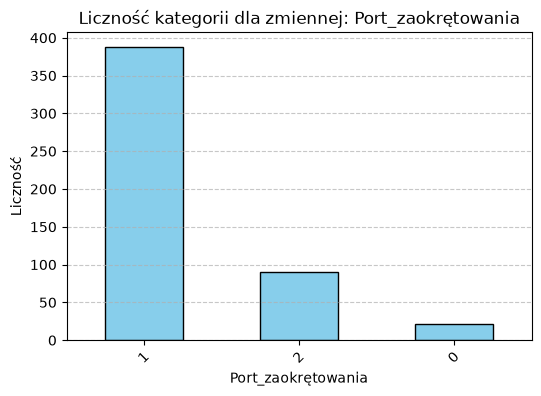

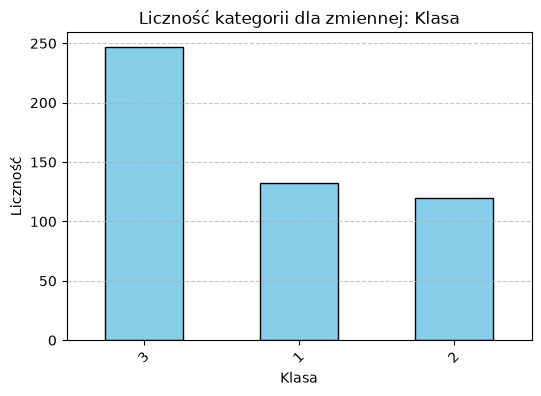

In [44]:
agh.plot_categorical_bars(X_train,cat_pred)

### 🎯 Wyjaśnienie kodowania `Port_zaokrętowania` w zbiorze Titanic

Na wykresie przedstawiono zakodowane kategorie zmiennej `Port_zaokrętowania`, która wskazuje port, z którego pasażerowie wsiedli na pokład Titanica. Liczby (`0`, `1`, `2`) to **nie losowe etykiety**, lecz efekt **target-based ordinal encoding**.

W tym przypadku celem (`y`) jest informacja, czy pasażer **przeżył** (`1`) czy **zginął** (`0`). Każda kategoria portu została zakodowana liczbą całkowitą zgodnie z **rosnącym odsetkiem zgonów** w tej kategorii.

#### Co to oznacza?

- Port o kodzie `0` miał **najmniejszy odsetek zgonów** (czyli **największą przeżywalność**),
- Port o kodzie `2` miał **najwyższy odsetek zgonów**,
- Dzięki temu model uczący się na danych może łatwiej zauważyć, że niektóre porty wiążą się z wyższym lub niższym ryzykiem.

To kodowanie **zachowuje porządek związany z wynikiem (survival)** i może wspomóc modele, które są wrażliwe na kolejność wartości, np. **regresję logistyczną** czy **drzewa decyzyjne**.


In [45]:
from sklearn.preprocessing import OneHotEncoder

# Kategoria, którą chcemy pominąć w kodowaniu (dla uniknięcia kolinearności)
drop_values = ['male']  # Musi być lista, nawet jeśli tylko jedna wartość

# Utworzenie obiektu OneHotEncoder z wybraną kategorią do pominięcia
one_hot_enc = OneHotEncoder(drop=drop_values, sparse_output=False)

# Dopasowanie enkodera do danych uczących
one_hot_enc_fit = one_hot_enc.fit(X_train[["Płeć"]])

# Przekształcenie danych uczących i testowych na zmienne zero-jedynkowe
train_encoded = one_hot_enc_fit.transform(X_train[["Płeć"]])
test_encoded = one_hot_enc_fit.transform(X_test[["Płeć"]])

# Pobranie nazw nowo utworzonych kolumn po kodowaniu
cols = one_hot_enc_fit.get_feature_names_out(["Płeć"])

# Wyświetlenie nazw kolumn dla kontroli
print(cols)

['Płeć_female']


### 🔍 One-Hot Encoding zmiennej `Płeć` z pominięciem kategorii `male`

W poniższym kodzie zastosowaliśmy kodowanie typu **one-hot encoding** do zmiennej `Płeć`, aby przekształcić ją na formę numeryczną odpowiednią dla modeli uczących się.

Zamiast tworzyć dwie kolumny (`Płeć_male`, `Płeć_female`), zdecydowaliśmy się **pominąć jedną z kategorii** (`male`) przy kodowaniu. To tzw. **drop-first** podejście, które pozwala uniknąć **kolinearności** między zmiennymi (sytuacji, w której jedna zmienna może być jednoznacznie wyrażona przez inne).

#### Co robi kod:
- Tworzy obiekt `OneHotEncoder` z parametrem `drop=['male']`, aby pominąć kategorię `male`,
- Dopasowuje encoder do danych uczących (`X_train`),
- Transformuje zarówno dane uczące, jak i testowe do postaci zero-jedynkowej,
- Generuje kolumnę `Płeć_female`, która przyjmuje wartość `1` dla kobiet i `0` dla mężczyzn (kategoria bazowa).

Dzięki temu zakodowana zmienna jest gotowa do użycia w modelu, który oczekuje danych liczbowych, a jednocześnie zachowujemy poprawność statystyczną modelu eliminując zbędną redundancję.


In [46]:
# Po zakodowaniu zmiennej 'Płeć' za pomocą OneHotEncoder,
# dodajemy nowe kolumny (zmienne zero-jedynkowe) do zbiorów X_train i X_test
X_train[cols] = train_encoded
X_test[cols] = test_encoded

In [47]:
display(X_train)

,Klasa,Płeć,Wiek,Cena_biletu,Port_zaokrętowania,Płeć_female
296,3,male,18.0,6.4958,1,0.0
116,2,male,19.0,36.7500,1,0.0
250,3,male,28.0,7.8958,1,0.0
91,3,male,67.5,7.7500,0,0.0
192,2,male,19.0,10.5000,1,0.0
...,...,...,...,...,...,...
585,3,male,28.5,16.1000,1,0.0
579,2,male,25.0,26.0000,1,0.0
411,2,female,34.0,10.5000,1,1.0
689,1,female,48.0,25.9292,1,1.0


In [48]:
# Po zakodowaniu zmiennej 'Płeć' (np. do postaci zero-jedynkowej), 
# usuwamy jej oryginalną wersję tekstową, aby nie wprowadzać jej ponownie do modelu
X_train = X_train.drop(columns="Płeć")
X_test = X_test.drop(columns="Płeć")

In [49]:
display(X_train)

,Klasa,Wiek,Cena_biletu,Port_zaokrętowania,Płeć_female
296,3,18.0,6.4958,1,0.0
116,2,19.0,36.7500,1,0.0
250,3,28.0,7.8958,1,0.0
91,3,67.5,7.7500,0,0.0
192,2,19.0,10.5000,1,0.0
...,...,...,...,...,...
585,3,28.5,16.1000,1,0.0
579,2,25.0,26.0000,1,0.0
411,2,34.0,10.5000,1,1.0
689,1,48.0,25.9292,1,1.0


## Model drzewa klasyfikacyjnego

Zbudujemy model drzew binarnych opary na algorytmie CART. Kluczowymi hiperparametrami metody są ustawienia odpowiedzialne za poziom skomplikowania drzewa.

* max_depth - Maksymalna głębokość drzewa - ogranicza złożoność modelu
* min_samples_split - Minimalna liczba próbek do podziału węzła - im większa, tym mniej złożone drzewo
* min_samples_leaf - Minimalna liczba próbek w liściu - zabezpiecza przed przeuczeniem

In [50]:
from sklearn.tree import DecisionTreeClassifier

# Inicjalizacja modelu
tree_model = DecisionTreeClassifier(
    max_depth=2,        # maksymalna głębokość drzewa (dla czytelności)
    random_state=42     # powtarzalność wyników
)

# Trenowanie modelu
tree_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

**Zobaczmy jakie drzewko udało nam się uzyskać**

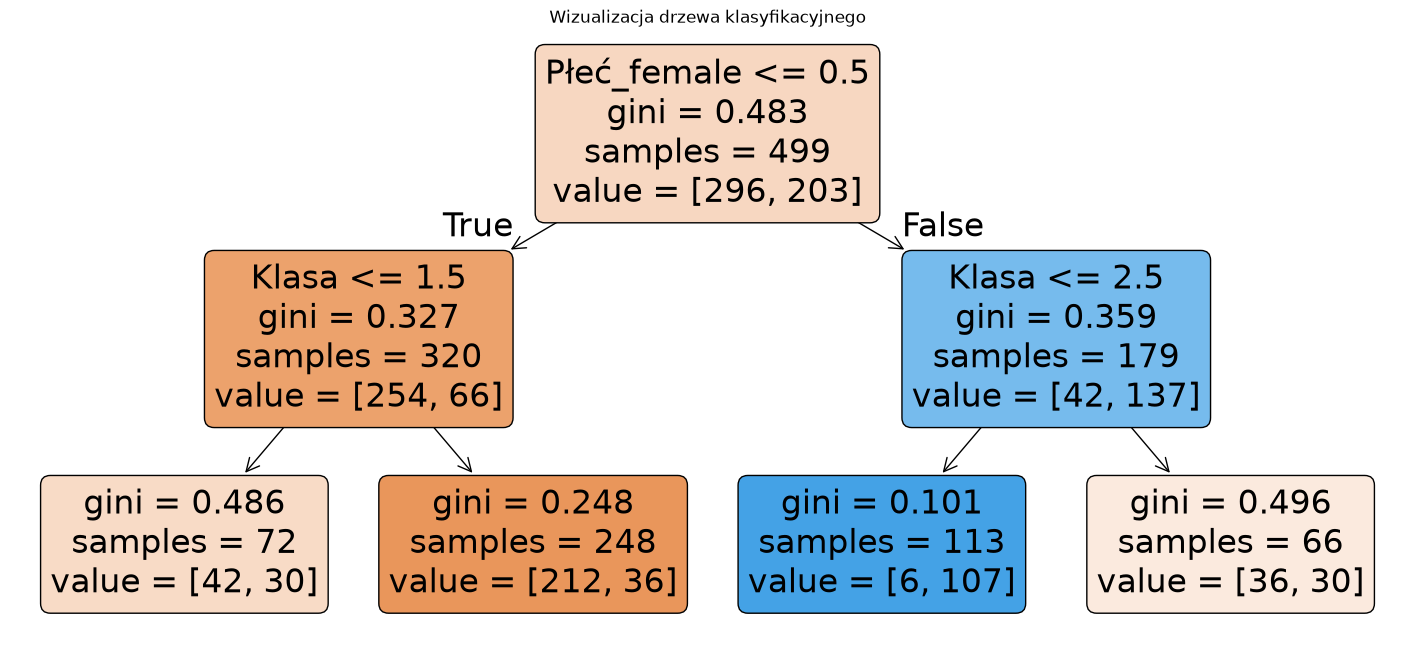

In [51]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))
plot_tree(tree_model, feature_names=X_train.columns, filled=True, rounded=True, max_depth=4)
plt.title("Wizualizacja drzewa klasyfikacyjnego")
plt.show()

**Zobaczmy jakie reguły udało nam się uzyskać?**

In [52]:
# Wyświetl pełne treści bez ucinania
pd.set_option("display.max_colwidth", None)

feature_names= [var for var in X_train.columns]

agh.extract_tree_rules(tree_model,feature_names)

,Reguła,Liczność,P(1),P(0)
0,Płeć_female > 0.50 AND Klasa ≤ 2.50,113,0.95,0.05
1,Płeć_female > 0.50 AND Klasa > 2.50,66,0.45,0.55
2,Płeć_female ≤ 0.50 AND Klasa ≤ 1.50,72,0.42,0.58
3,Płeć_female ≤ 0.50 AND Klasa > 1.50,248,0.15,0.85


**Jak wyglądają predykcje modelu?**

In [53]:
# Predykcje na zbiorze uczącym
y_pred = tree_model.predict_proba(X_train)

y_pred_0 = y_pred[:, 0]
y_pred_1 = y_pred[:, 1]

In [54]:
# Zobaczmy fragment wyników
y_pred[:20]

array([[0.85483871, 0.14516129],
       [0.85483871, 0.14516129],
       [0.85483871, 0.14516129],
       [0.85483871, 0.14516129],
       [0.85483871, 0.14516129],
       [0.05309735, 0.94690265],
       [0.85483871, 0.14516129],
       [0.58333333, 0.41666667],
       [0.05309735, 0.94690265],
       [0.85483871, 0.14516129],
       [0.05309735, 0.94690265],
       [0.05309735, 0.94690265],
       [0.58333333, 0.41666667],
       [0.85483871, 0.14516129],
       [0.05309735, 0.94690265],
       [0.05309735, 0.94690265],
       [0.58333333, 0.41666667],
       [0.85483871, 0.14516129],
       [0.05309735, 0.94690265],
       [0.85483871, 0.14516129]])

### 📊 Fragment wyników predykcji: `predict_proba()[:20]`

Powyższy wynik pokazuje 20 pierwszych wierszy tablicy predykcji uzyskanej z `model.predict_proba(X_test)`.

Każdy wiersz zawiera **dwa elementy**:

- Pierwszy element: prawdopodobieństwo przynależności do klasy `0` (np. "nie przeżył"),
- Drugi element: prawdopodobieństwo przynależności do klasy `1` (np. "przeżył").

#### 🧠 Przykład interpretacji:
- `[0.70967742, 0.29032258]` → model przewiduje 29% prawdopodobieństwa dla klasy `1`,
- `[0.0375, 0.9625]` → bardzo wysokie prawdopodobieństwo klasy `1`,
- `[0.5, 0.5]` → model nie ma preferencji – brak jednoznacznej decyzji.

📌 Te wartości służą do:
- tworzenia wykresów ROC i innych,
- testowania różnych punktów odcięcia (`threshold`).

### 🧠 Interpretacja `predict_proba`

```python
predict_proba(X_train)[:, 0] → prawdopodobieństwa klasy 0 – nie przeżył

predict_proba(X_train)[:, 1] → prawdopodobieństwa klasy 1 – przeżył


Która klasa będzie dla nas klasą pozytywną?

### 🧠 Kiedy klasę nazywamy „pozytywną”?

To, która klasa jest uznawana za pozytywną (`1`), jest decyzją **użytkownika lub twórcy zbioru danych**.  
Często:
- W klasyfikacji medycznej: `1` = przypadek niepożądany (np. zgon, choroba),
- W scoringu kredytowym: `1` = default, oszustwo,
- W Titanicach z Kaggle: `1` = przeżył (czyli przypadek „pozytywny” w sensie dosłownym).

📌 Klasa pozytywna wpływa na to, co oznacza:
- czułość (recall),
- precision,
- AUC,
- KS itp.

🧠 Kluczem jest **spójność i świadomość interpretacji**, a nie sama wartość `0` lub `1`.




#### Po tym przydługim wstępie spróvujemy ocenić model za pomocą krzywej ROC 

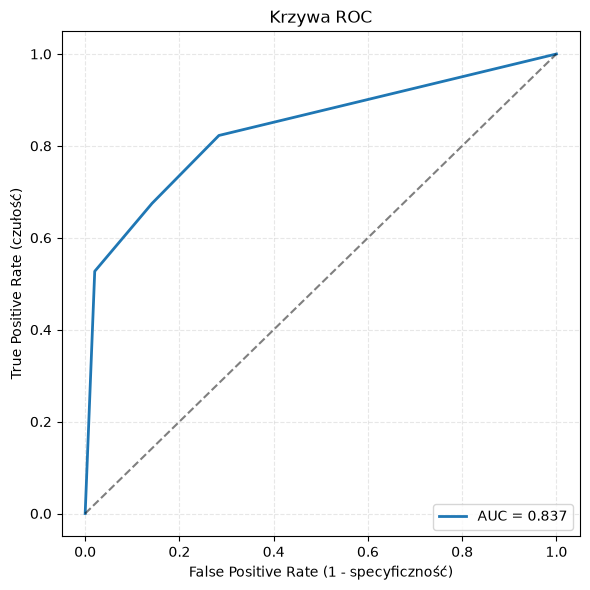

In [55]:
agh.plot_roc_curve(y_train,y_pred_1,1)

### 📈 Krzywa ROC i wskaźnik AUC – wprowadzenie

Krzywa ROC (Receiver Operating Characteristic) pokazuje, jak dobrze nasz model rozróżnia między dwiema klasami (np. przeżył vs zginął). 

Na wykresie:
- Oś X to **False Positive Rate** (czyli 1 - specyficzność),
- Oś Y to **True Positive Rate** (czyli czułość).

Im bardziej krzywa ROC **odchyla się w górę od przekątnej**, tym lepszy model.

---

### 🧮 AUC – Area Under the Curve

- AUC to **pole pod krzywą ROC** – im większe, tym lepiej.
- AUC mówi, z jakim prawdopodobieństwem model poprawnie odróżni przypadek pozytywny od negatywnego.

#### 🔢 Jak interpretować AUC?

| AUC       | Jakość modelu         |
|-----------|------------------------|
| 0.90–1.00 | Doskonały              |
| 0.80–0.90 | Bardzo dobry           |
| 0.70–0.80 | Dobry                  |
| 0.60–0.70 | Przeciętny             |
| 0.50–0.60 | Słaby (prawie losowy) |
| 0.50      | Model losowy (brak wartości) |

---

### ✅ Wnioski z wykresu

- Nasz model ma **AUC = 0.837**, co oznacza, że jest **bardzo dobry** w klasyfikowaniu.
- Krzywa znacząco odchyla się od przekątnej → model dobrze rozróżnia klasy.


### Spróbujmy teraz ocenić model za pomocą walidacji krzyżowej 

In [56]:
# Zaczynamy od niezbędnych bibliotek
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Definiujemy podział z ustalonym seedem
cv_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)


y_pred_cv_proba = cross_val_predict(
    estimator=tree_model,
    X=X_train,
    y=y_train,
    cv=cv_split,
    method='predict_proba'
)

y_pred_0_CV = y_pred_cv_proba[:, 0]
y_pred_1_CV = y_pred_cv_proba[:, 1]

**Porównajmy uzyskane wyniki**

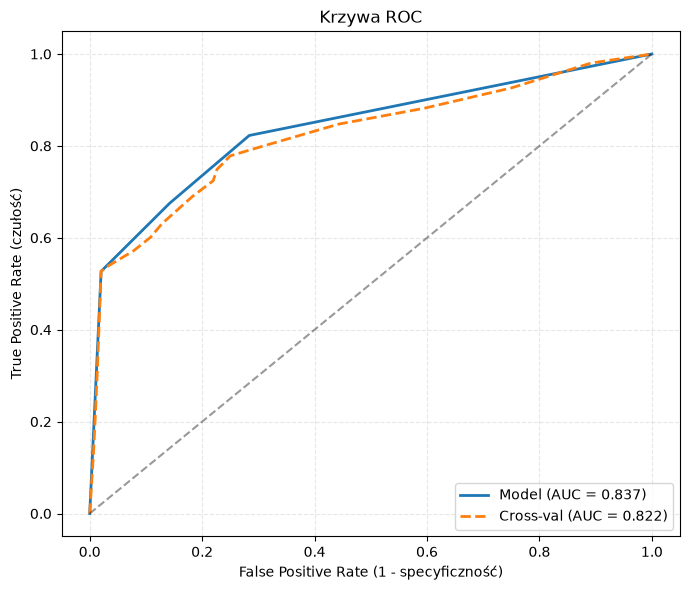

In [57]:
agh.plot_roc_curve_compare(y_train,y_pred_1,1,y_score_cv=y_pred_1_CV)

**Dodatkowo ocenimy model za pomocą miary KS oraz zbadamy punkt odcięcia**

In [58]:
agh.evaluate_auc_ks_model_vs_cv(y_train,y_pred_1,y_pred_1_CV,1)

,Podejście,AUC,KS,Threshold_KS
0,Model klasyczny,0.837388,0.538876,0.416667
1,Cross-validation,0.822410,0.528325,0.406780


### 📊 Wskaźnik KS – uzupełnienie AUC

KS (Kolmogorov–Smirnov) to **miara separacji** między rozkładami przewidywań dla klasy pozytywnej i negatywnej. Pokazuje, jak dobrze model odróżnia te dwie grupy.

- Im **wyższy KS**, tym lepiej – większa różnica między prawdopodobieństwami dla obu klas.
- Często uznaje się, że **KS > 0.4** to dobry model, **> 0.6** to bardzo dobry wynik.

---

### 🎯 Threshold_KS

Punkt, w którym **KS osiąga maksimum**, może być wykorzystany jako **optymalny próg odcięcia** przy decyzji klasyfikacyjnej (np. czy uznać pacjenta za zagrożonego, klienta za odchodzącego itd.).

W powyższej tabeli:
- Model klasyczny osiąga KS = `0.538` przy progu ≈ `0.417`,
- Model z walidacją krzyżową ma KS = `0.528` przy progu ≈ `0.407`.

To potwierdza dobrą jakość modeli i może służyć do automatycznego wyboru **punktu decyzyjnego**.


**Wprowadzamy próg zaproponowany przez KS na zbiorze CV**

#### Zacznijmy od macierzy pomyłek

In [59]:
from sklearn.metrics import confusion_matrix

agh.confusion_matrix_with_labels(y_train, y_pred_1, threshold=0.407)

,Obserwowane TAK,Obserwowane NIE,Razem
Przewidywane TAK,212 (TP),36 (FP),248
Przewidywane NIE,84 (FN),167 (TN),251
Razem,296,203,499


#### A teraz miary jakości oparte na tej macierzy

In [60]:
agh.basic_metrics_summary(y_train,y_pred_1,threshold=0.407)

,Skrót,Miara (PL),Wartość,Wzór
0,SENS,Czułość (Sensitivity),0.8227,TP / (TP + FN)
1,SPEC,Specyficzność (Specificity),0.7162,TN / (TN + FP)
2,PREC,Precyzja (Precision),0.6653,TP / (TP + FP)
3,NPV,Ujemna wartość predykcyjna (NPV),0.8548,TN / (TN + FN)
4,ACC,Dokładność (Accuracy),0.7595,(TP + TN) / (TP + TN + FP + FN)
5,F1,F1-score (średnia precyzji i czułości),0.7357,2 * PREC * SENS / (PREC + SENS)


### 📊 Interpretacja podstawowych miar jakości – Titanic

Przyjmujemy, że klasa pozytywna (`1`) oznacza **przeżycie** pasażera.  
Poniżej znajduje się charakterystyka najważniejszych metryk w tym kontekście:

| Skrót | Miara (PL)                            | Interpretacja w kontekście Titanica                                                                                      |
|-------|----------------------------------------|--------------------------------------------------------------------------------------------------------------------------|
| **SENS** | Czułość (Sensitivity)               | Spośród wszystkich pasażerów, którzy **przeżyli**, ile z nich model **prawidłowo rozpoznał** jako ocalonych?<br>🧠 Im wyższa czułość, tym mniej "przeoczonych" ocalonych. |
| **SPEC** | Specyficzność (Specificity)         | Spośród tych, którzy **nie przeżyli**, ilu model poprawnie zaklasyfikował jako ofiary?<br>🧠 Im wyższa specyficzność, tym mniej fałszywych alarmów. |
| **PREC** | Precyzja (Precision)               | Spośród pasażerów **zaklasyfikowanych jako ocaleni**, ilu faktycznie przeżyło?<br>🧠 Wskaźnik wiarygodności pozytywnych klasyfikacji. |
| **NPV** | Ujemna wartość predykcyjna (NPV)    | Spośród pasażerów zaklasyfikowanych jako ofiary, ilu **rzeczywiście zginęło**?<br>🧠 Wskaźnik wiarygodności negatywnych klasyfikacji. |
| **ACC** | Dokładność (Accuracy)               | Jaki procent wszystkich przewidywań był trafny (zarówno przeżycia, jak i zgonu)?<br>🧠 Wrażliwa na niezrównoważone dane — na szczęście Titanic jest względnie zbalansowany. |
| **F1** | F1-score (średnia precyzji i czułości) | Miara kompromisowa między **precyzją** a **czułością**.<br>🧠 Przydatna, gdy zależy nam na równowadze i stabilności klasyfikacji. |

---

### 🧠 Co jest szczególnie ważne w danych Titanic?

- **Czułość (SENS)**: nie chcemy „przeoczyć” nikogo, kto faktycznie przeżył.
- **Precyzja (PREC)**: jeśli mówimy komuś „przeżyjesz”, to chcemy, by było to prawdopodobne.
- **F1-score**: dobra zbiorcza miara efektywności – pokazuje, czy model nie faworyzuje jednej klasy.


**Dodatkowo 'nie zaszkodzi' zerknąć na ważność zmiennych**

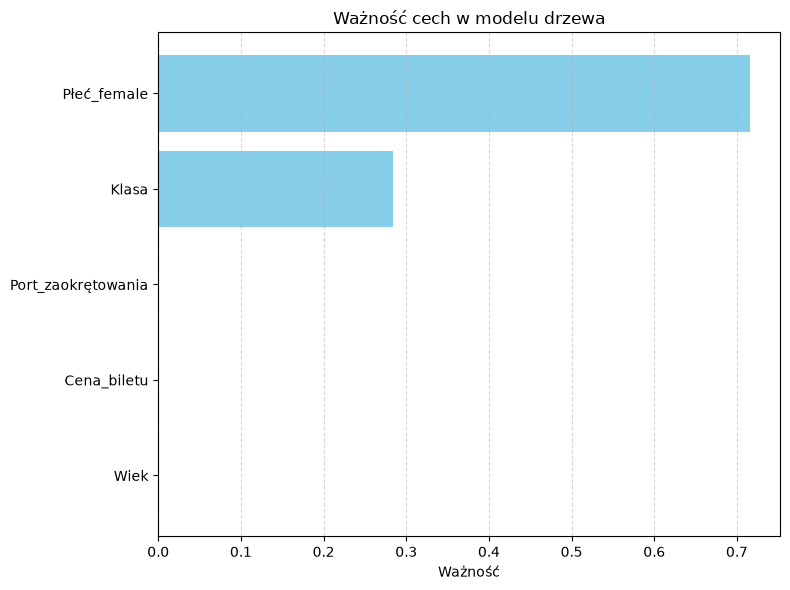

In [61]:
agh.tree_model_importance(tree_model,feature_names)

📘 **Zadanie do samodzielnego sprawdzenia**

Sprawdź, jak zmienia się jakość modelu:

1. Przy różnych wartościach **głębokości drzewa decyzyjnego** (`max_depth`).
2. Dla różnych wartości **punktu odcięcia** (threshold), np. od `0.3` do `0.6`.

👉 Zwróć uwagę, jak zmienia się AUC, KS oraz odsetek poprawnie zaklasyfikowanych przypadków.  
Zastanów się, czy bardziej złożone drzewo zawsze daje lepsze wyniki i jak wybór punktu odcięcia wpływa na czułość i swoistość klasyfikatora.


### Regresja logistyczna

In [62]:
# Dwie biblioteki - jedna nam pozwoli opisać model a druga pozwoli na predykcje

from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm

In [63]:
# Budowa modelu + tabelka z interpretacją
summary_df, model_logit = agh.fit_logit_dual(X_train, y_train)

In [64]:
display(summary_df)  # interpretacja

,Zmienna,Współczynnik (log-odds),Iloraz szans (OR),p-value,Interpretacja
const,const,2.4008,11.0322,0.0059,Zwiększa szanse
Klasa,Klasa,-1.3612,0.2563,0.0000,Zmniejsza szanse
Wiek,Wiek,-0.0402,0.9606,0.0000,Zmniejsza szanse
Cena_biletu,Cena_biletu,-0.0061,0.9939,0.4893,Zmniejsza szanse
Port_zaokrętowania,Port_zaokrętowania,0.4851,1.6243,0.0938,Zwiększa szanse
Płeć_female,Płeć_female,2.5459,12.7543,0.0000,Zwiększa szanse


📌 **Uwaga dotycząca istotności statystycznej zmiennych**

W powyższej tabeli widać, że zmienne `Cena_biletu` oraz `Port_zaokrętowania` mają **p-value wyższe niż 0.05**, co oznacza, że ich współczynniki **nie różnią się statystycznie istotnie od zera**.

🔍 W podejściu statystycznym oznacza to, że nie mamy wystarczających dowodów, by stwierdzić, że te zmienne wpływają na przeżycie — ich efekt może być przypadkowy.

➡️ Na tej podstawie można rozważyć **eliminację tych zmiennych z modelu**, co może prowadzić do uproszczenia modelu bez utraty jakości predykcyjnej.

ℹ️ **Ważne:** brak istotności może również wynikać z tego, że dana zmienna **niesie podobną informację jak inne zmienne w modelu** (np. `Cena_biletu` może być skorelowana z `Klasą`). W takim przypadku efekt jednej zmiennej może być „przykryty” przez inną.


In [65]:
# Predykcje na zbiorze uczącym
y_logit_pred = model_logit.predict_proba(X_train)  # predykcja

In [66]:
y_logit_pred_0 = y_logit_pred[:, 0]
y_logit_pred_1 = y_logit_pred[:, 1]

# Zobaczmy fragment wyników
y_logit_pred[:20]

array([[0.86964344, 0.13035656],
       [0.6934201 , 0.3065799 ],
       [0.90235242, 0.09764758],
       [0.98326644, 0.01673356],
       [0.70447498, 0.29552502],
       [0.07002194, 0.92997806],
       [0.79259382, 0.20740618],
       [0.69725063, 0.30274937],
       [0.2625276 , 0.7374724 ],
       [0.87301357, 0.12698643],
       [0.04507995, 0.95492005],
       [0.22512309, 0.77487691],
       [0.52606189, 0.47393811],
       [0.89640598, 0.10359402],
       [0.08955503, 0.91044497],
       [0.11828118, 0.88171882],
       [0.7072705 , 0.2927295 ],
       [0.81681861, 0.18318139],
       [0.23090758, 0.76909242],
       [0.9278395 , 0.0721605 ]])

In [67]:
display(summary_df)  # interpretacja

,Zmienna,Współczynnik (log-odds),Iloraz szans (OR),p-value,Interpretacja
const,const,2.4008,11.0322,0.0059,Zwiększa szanse
Klasa,Klasa,-1.3612,0.2563,0.0000,Zmniejsza szanse
Wiek,Wiek,-0.0402,0.9606,0.0000,Zmniejsza szanse
Cena_biletu,Cena_biletu,-0.0061,0.9939,0.4893,Zmniejsza szanse
Port_zaokrętowania,Port_zaokrętowania,0.4851,1.6243,0.0938,Zwiększa szanse
Płeć_female,Płeć_female,2.5459,12.7543,0.0000,Zwiększa szanse


### 🧠 Prawdopodobieństwo, szansa i iloraz szans – proste wyjaśnienie

Na podstawie wyników modelu widzimy, że zmienna `Płeć_female` ma **iloraz szans (OR) ≈ 12.75**.

🔍 Co to oznacza? Wyjaśnijmy pojęcia krok po kroku na przykładzie:

---

#### 1️⃣ **Prawdopodobieństwo (probability)**


To część (ułamek) przypadków, w których dane zdarzenie zachodzi:  
> Jeśli spośród 100 kobiet przeżyło 80, to **prawdopodobieństwo** przeżycia kobiety wynosi:  
> **80 / 100 = 0.8** (czyli 80%)

---

#### 2️⃣ **Szansa (odds)**

To stosunek liczby sukcesów do liczby porażek:  
> Skoro 80 kobiet przeżyło, a 20 nie, to szansa wynosi:  
> **80 / 20 = 4**

Czyli kobieta ma **4 razy większą szansę przeżyć niż nie przeżyć**. Można powidzieć, że szansa przeżycia wynosi 4 do 1

---

#### 3️⃣ **Iloraz szans (OR – odds ratio)**

To stosunek szans dwóch grup – np. kobiet do mężczyzn.  
> Jeśli mężczyzna ma odds ≈ 0.43, a kobieta ma odds = 4, to:  
> **OR = 4 / 0.43 ≈ 9.3**

W naszym modelu OR wynosi **ok. 12.75**, czyli:
> **Szansa przeżycia kobiety jest ponad 12 razy większa niż szansa przeżycia mężczyzny**, przy założeniu, że pozostałe zmienne są stałe.

---

🔎 **Podsumowanie:**

| Pojęcie              | Co oznacza?                                               |
|----------------------|------------------------------------------------------------|
| Prawdopodobieństwo   |  Część przypadków, w których zdarzenie zachodzi (np. 80%)                                 |
| Szansa (odds)        | Ilu przeżywa / ilu nie przeżywa                           |
| Iloraz szans (OR)    | Szansa jednej grupy / szansa drugiej grupy               |

In [68]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Ustalony podział CV (np. 5-krotny, ze stałym seedem)
cv_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

# Predykcja probabilistyczna z CV dla regresji logistycznej
y_pred_logit_cv_proba = cross_val_predict(
    estimator=model_logit,
    X=X_train,
    y=y_train,
    cv=cv_split,
    method='predict_proba'
)

# Oddzielne kolumny: prawdopodobieństwa klas 0 i 1
y_pred_logit_0_cv = y_pred_logit_cv_proba[:, 0]
y_pred_logit_1_cv = y_pred_logit_cv_proba[:, 1]

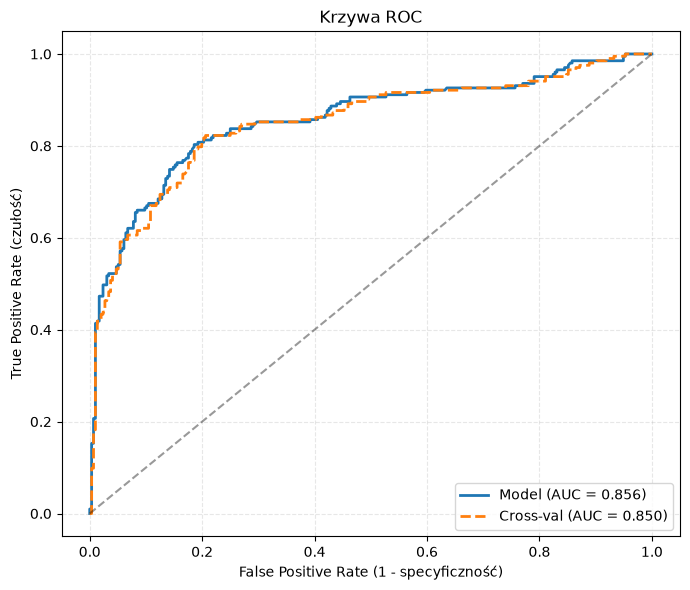

In [69]:
agh.plot_roc_curve_compare(y_train,y_logit_pred_1,1,y_score_cv=y_pred_logit_1_cv)

In [70]:
agh.evaluate_auc_ks_model_vs_cv(y_train,y_logit_pred_1,y_pred_logit_1_cv,1)

,Podejście,AUC,KS,Threshold_KS
0,Model klasyczny,0.856311,0.617145,0.415417
1,Cross-validation,0.850270,0.616579,0.369081


In [71]:
summary_reduced, model_logit_reduced, zmienne = agh.stepwise_logit_summary(X_train, y_train)

In [72]:
display(zmienne)

['Klasa', 'Wiek', 'Płeć_female']

In [73]:
display(summary_reduced)

,Zmienna,Współczynnik (log-odds),Iloraz szans (OR),p-value,Interpretacja
const,const,2.7235,15.2337,0.0,Zwiększa szanse
Klasa,Klasa,-1.3335,0.2636,0.0,Zmniejsza szanse
Wiek,Wiek,-0.0395,0.9613,0.0,Zmniejsza szanse
Płeć_female,Płeć_female,2.5269,12.5143,0.0,Zwiększa szanse


Iloraz szans (OR) = 0.96 dla wieku oznacza, że **z każdym kolejnym rokiem życia** szanse przeżycia spadają o ok. 4%.

To może się wydawać mało, ale:

- dla osoby o **10 lat starszej**, szansa przeżycia spada o ok.  
  0.96^10 ≈ 0.66, czyli spadek o około 34%

- dla różnicy **20 lat**:  
  0.96^20 ≈ 0.44, czyli spadek o ponad 55%

🔍 Dlatego nawet niewielki OR może mieć **duży praktyczny wpływ**, jeśli zmienna ma szeroki zakres wartości.


In [74]:
# 🔍 Predykcja na zbiorze uczącym (model uproszczony)
y_logit_reduced_pred = model_logit_reduced.predict_proba(X_train[zmienne])  # predykcja

# Rozdzielenie na klasy 0 i 1
y_logit_reduced_pred_0 = y_logit_reduced_pred[:, 0]
y_logit_reduced_pred_1 = y_logit_reduced_pred[:, 1]

# Podgląd wyników
y_logit_reduced_pred[:20]

array([[0.86871962, 0.13128038],
       [0.68842248, 0.31157752],
       [0.89961465, 0.10038535],
       [0.96741727, 0.03258273],
       [0.68842248, 0.31157752],
       [0.06187401, 0.93812599],
       [0.77689319, 0.22310681],
       [0.65383645, 0.34616355],
       [0.24293978, 0.75706022],
       [0.87213973, 0.12786027],
       [0.07128265, 0.92871735],
       [0.21105326, 0.78894674],
       [0.49219128, 0.50780872],
       [0.8940029 , 0.1059971 ],
       [0.12339984, 0.87660016],
       [0.10791152, 0.89208848],
       [0.67413022, 0.32586978],
       [0.80207038, 0.19792962],
       [0.21614717, 0.78385283],
       [0.92387608, 0.07612392]])

In [75]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Podział do CV z ustalonym seedem
cv_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

y_logit_reduced_cv_proba = cross_val_predict(
    estimator=model_logit_reduced,
    X=X_train[zmienne],
    y=y_train,
    cv=cv_split,
    method='predict_proba'
)

# Rozdzielenie na klasy 0 i 1
y_logit_reduced_cv_0 = y_logit_reduced_cv_proba[:, 0]
y_logit_reduced_cv_1 = y_logit_reduced_cv_proba[:, 1]

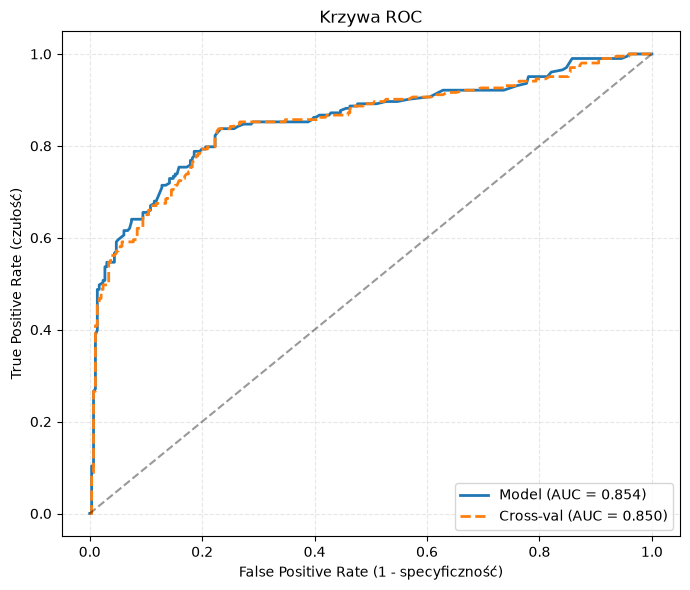

In [76]:
agh.plot_roc_curve_compare(y_train,y_logit_reduced_pred_1,1,y_score_cv=y_logit_reduced_cv_1)

In [77]:
agh.evaluate_auc_ks_model_vs_cv(y_train,y_logit_reduced_pred_1,y_logit_reduced_cv_1,1)

,Podejście,AUC,KS,Threshold_KS
0,Model klasyczny,0.854414,0.604330,0.339332
1,Cross-validation,0.849745,0.607709,0.343902


In [78]:
from sklearn.metrics import confusion_matrix

agh.confusion_matrix_with_labels(y_train, y_logit_reduced_pred_1, threshold=0.34)

,Obserwowane TAK,Obserwowane NIE,Razem
Przewidywane TAK,228 (TP),34 (FP),262
Przewidywane NIE,68 (FN),169 (TN),237
Razem,296,203,499


In [79]:
agh.basic_metrics_summary(y_train,y_logit_reduced_pred_1,threshold=0.34)

,Skrót,Miara (PL),Wartość,Wzór
0,SENS,Czułość (Sensitivity),0.8325,TP / (TP + FN)
1,SPEC,Specyficzność (Specificity),0.7703,TN / (TN + FP)
2,PREC,Precyzja (Precision),0.7131,TP / (TP + FP)
3,NPV,Ujemna wartość predykcyjna (NPV),0.8702,TN / (TN + FN)
4,ACC,Dokładność (Accuracy),0.7956,(TP + TN) / (TP + TN + FP + FN)
5,F1,F1-score (średnia precyzji i czułości),0.7682,2 * PREC * SENS / (PREC + SENS)


### Sieci neuronowe

In [80]:
from sklearn.neural_network import MLPClassifier

# Model MLP na domyślnych ustawieniach
model_mlp = MLPClassifier(random_state=seed)
model_mlp.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",200
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [81]:
# 🔍 Predykcja na zbiorze uczącym (model MLP)
y_mlp_pred = model_mlp.predict_proba(X_train)  # predykcja

# Rozdzielenie na prawdopodobieństwa klas 0 i 1
y_mlp_pred_0 = y_mlp_pred[:, 0]
y_mlp_pred_1 = y_mlp_pred[:, 1]

# Podgląd wyników
y_mlp_pred[:20]

array([[0.86463063, 0.13536937],
       [0.66347681, 0.33652319],
       [0.89286306, 0.10713694],
       [0.97364652, 0.02635348],
       [0.79588381, 0.20411619],
       [0.08839765, 0.91160235],
       [0.82473291, 0.17526709],
       [0.74323067, 0.25676933],
       [0.27524955, 0.72475045],
       [0.87032192, 0.12967808],
       [0.06643448, 0.93356552],
       [0.31957693, 0.68042307],
       [0.64460259, 0.35539741],
       [0.88663771, 0.11336229],
       [0.10314333, 0.89685667],
       [0.07309192, 0.92690808],
       [0.8181656 , 0.1818344 ],
       [0.83668615, 0.16331385],
       [0.32035528, 0.67964472],
       [0.92804181, 0.07195819]])

In [82]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

cv_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

# Predykcje probabilistyczne w CV
y_mlp_cv_proba = cross_val_predict(
    estimator=model_mlp,
    X=X_train,
    y=y_train,
    cv=cv_split,
    method='predict_proba'
)

# Rozdzielenie na prawdopodobieństwa klas 0 i 1
y_mlp_cv_pred_0 = y_mlp_cv_proba[:, 0]
y_mlp_cv_pred_1 = y_mlp_cv_proba[:, 1]

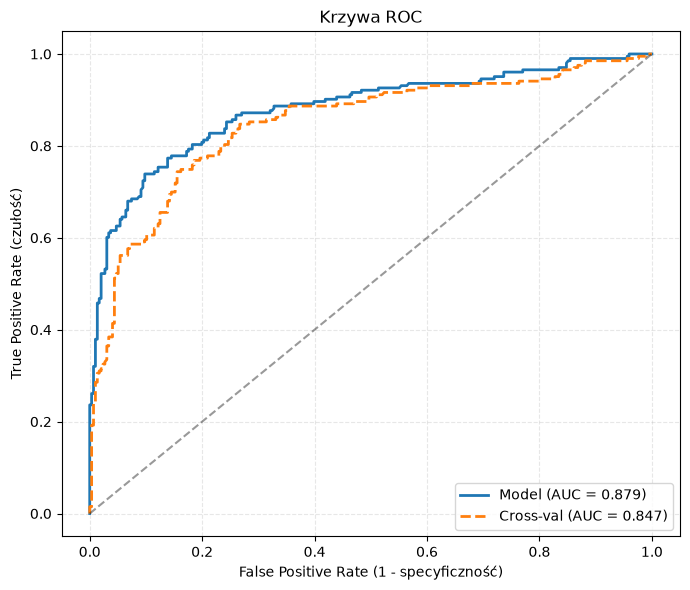

In [83]:
agh.plot_roc_curve_compare(y_train,y_mlp_pred_1,1,y_score_cv=y_mlp_cv_pred_1)

In [84]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'hidden_layer_sizes': [(10,), (50,), (100,), (50, 50)],
    'solver': ['adam', 'lbfgs'],
    'alpha': [0.0001, 0.001]
}

mlp_grid = MLPClassifier(max_iter=1000, random_state=seed)

grid_search = GridSearchCV(mlp_grid, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Najlepsze parametry:", grid_search.best_params_)
print("Najlepszy wynik AUC (CV):", round(grid_search.best_score_, 4))

# Najlepszy model
model_mlp_best = grid_search.best_estimator_

Najlepsze parametry: {'alpha': 0.0001, 'hidden_layer_sizes': (50,), 'solver': 'adam'}
Najlepszy wynik AUC (CV): 0.8516


### 🧠 Wyjaśnienie hiperparametrów sieci neuronowej (`MLPClassifier`)

W sieci neuronowej możemy dostosować wiele tzw. **hiperparametrów**, które wpływają na strukturę sieci i sposób jej uczenia. W poniższym przykładzie badamy różne kombinacje ustawień w ramach `GridSearchCV`:

#### 🔧 Ustawiony zakres hiperparametrów:

```python
param_grid = {
    'hidden_layer_sizes': [(10,), (50,), (100,), (50, 50)],
    'solver': ['adam', 'lbfgs'],
    'alpha': [0.0001, 0.001]
}
```

---

#### 🔹 `hidden_layer_sizes`

To struktura sieci, czyli liczba neuronów w warstwach ukrytych:

- `(10,)` – jedna warstwa ukryta z 10 neuronami  
- `(50,)` – jedna warstwa z 50 neuronami  
- `(100,)` – jedna warstwa z 100 neuronami  
- `(50, 50)` – **dwie warstwy**, każda po 50 neuronów

📌 Im więcej warstw i neuronów, tym model jest bardziej złożony — ale może też się łatwiej przeuczyć i działać wolniej.

---

#### 🔹 `solver`

To algorytm używany do optymalizacji wag sieci, czyli „uczenia się” na danych:

- `adam` – szybki i skuteczny algorytm oparty na gradientach (często domyślny wybór dla dużych zbiorów)  
- `lbfgs` – dokładniejszy, ale wolniejszy algorytm oparty na metodzie Newtona (często lepszy przy małych zbiorach)

---

#### 🔹 `alpha`

To współczynnik **regularyzacji L2**, który zapobiega przeuczeniu (overfittingowi):

- `0.0001` – słaba regularyzacja (większa swoboda dla wag)  
- `0.001` – silniejsza regularyzacja (model mniej podatny na dopasowanie do szumów w danych)

🔍 Regularyzacja dodaje „karę” za zbyt duże wagi, aby model był bardziej ogólny.

---

### ✅ Co robi `GridSearchCV`?

`GridSearchCV` testuje każdą możliwą kombinację hiperparametrów i wybiera najlepszą — np. tę, która osiąga najwyższą wartość AUC w walidacji krzyżowej (`cv`).


In [85]:
# 🔍 Predykcja na zbiorze uczącym (model MLP – wersja zoptymalizowana)
y_mlp_best_pred = model_mlp_best.predict_proba(X_train)  # predykcja

# Rozdzielenie na prawdopodobieństwa klas 0 i 1
y_mlp_best_pred_0 = y_mlp_best_pred[:, 0]
y_mlp_best_pred_1 = y_mlp_best_pred[:, 1]

# Podgląd wyników
y_mlp_best_pred[:20]

array([[0.8866514 , 0.1133486 ],
       [0.71015042, 0.28984958],
       [0.89834216, 0.10165784],
       [0.98923231, 0.01076769],
       [0.78591735, 0.21408265],
       [0.05743965, 0.94256035],
       [0.8403841 , 0.1596159 ],
       [0.72422641, 0.27577359],
       [0.28262168, 0.71737832],
       [0.89441452, 0.10558548],
       [0.06389903, 0.93610097],
       [0.2969523 , 0.7030477 ],
       [0.61806675, 0.38193325],
       [0.89748071, 0.10251929],
       [0.08401074, 0.91598926],
       [0.07918134, 0.92081866],
       [0.83673584, 0.16326416],
       [0.86192446, 0.13807554],
       [0.30151378, 0.69848622],
       [0.94113789, 0.05886211]])

In [86]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

cv_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

y_mlp_best_cv_proba = cross_val_predict(
    estimator=model_mlp_best,
    X=X_train,
    y=y_train,
    cv=cv_split,
    method='predict_proba'
)

# Rozdzielenie na prawdopodobieństwa klas 0 i 1
y_mlp_best_cv_pred_0 = y_mlp_best_cv_proba[:, 0]
y_mlp_best_cv_pred_1 = y_mlp_best_cv_proba[:, 1]

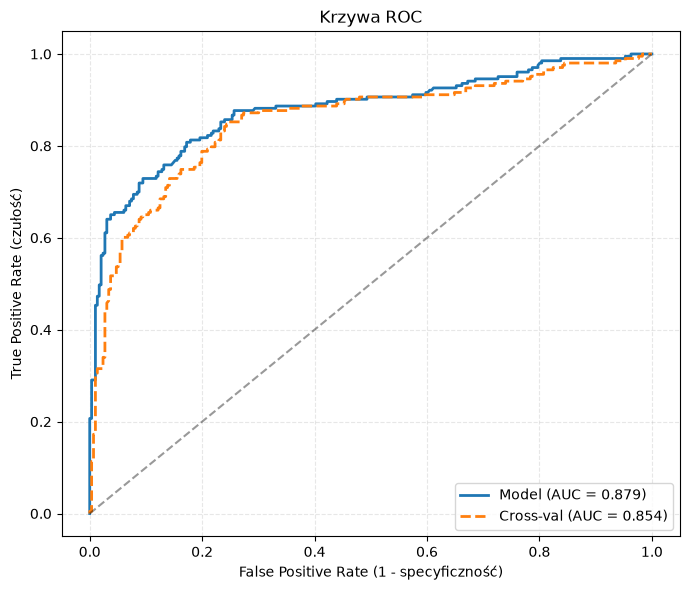

In [87]:
agh.plot_roc_curve_compare(y_train,y_mlp_best_pred_1,1,y_score_cv=y_mlp_best_cv_pred_1)

### Wybieramy model - skoro nie ma różnicy... to po co przepłacać?

In [88]:
# 🔍 Predykcja na zbiorze testowym (model uproszczony)
y_logit_reduced_test_pred = model_logit_reduced.predict_proba(X_test[zmienne])  # predykcja

# Rozdzielenie na klasy 0 i 1
y_logit_reduced_test_pred_0 = y_logit_reduced_test_pred[:, 0]
y_logit_reduced_test_pred_1 = y_logit_reduced_test_pred[:, 1]

# Podgląd wyników
y_logit_reduced_test_pred[:20]

array([[0.94098603, 0.05901397],
       [0.60233387, 0.39766613],
       [0.45231259, 0.54768741],
       [0.91005088, 0.08994912],
       [0.36464738, 0.63535262],
       [0.2779466 , 0.7220534 ],
       [0.2374057 , 0.7625943 ],
       [0.3576506 , 0.6423494 ],
       [0.08667979, 0.91332021],
       [0.8940029 , 0.1059971 ],
       [0.72605803, 0.27394197],
       [0.87548351, 0.12451649],
       [0.72502732, 0.27497268],
       [0.91250268, 0.08749732],
       [0.73795501, 0.26204499],
       [0.27292739, 0.72707261],
       [0.19156171, 0.80843829],
       [0.87548351, 0.12451649],
       [0.878752  , 0.121248  ],
       [0.75700581, 0.24299419]])

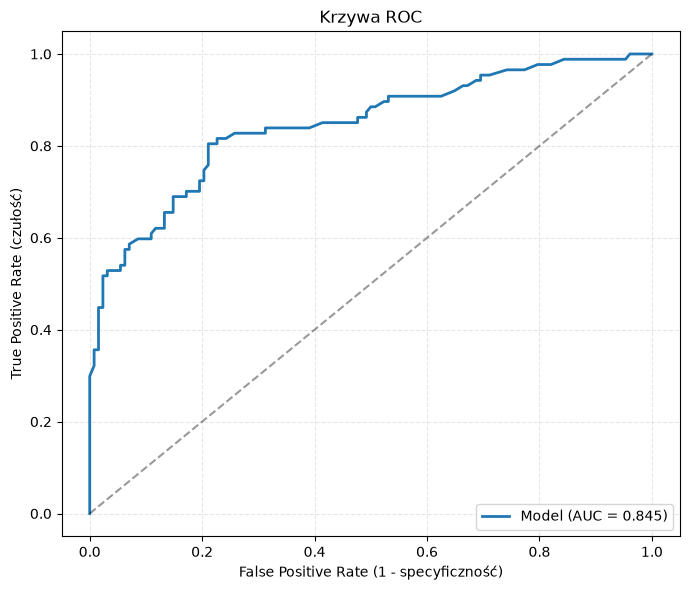

In [89]:
agh.plot_roc_curve_compare(y_test,y_logit_reduced_test_pred_1,1)

In [90]:
from sklearn.metrics import confusion_matrix

agh.confusion_matrix_with_labels(y_test, y_logit_reduced_test_pred_1, threshold=0.34)

,Obserwowane TAK,Obserwowane NIE,Razem
Przewidywane TAK,91 (TP),15 (FP),106
Przewidywane NIE,37 (FN),72 (TN),109
Razem,128,87,215


In [91]:
agh.basic_metrics_summary(y_test,y_logit_reduced_test_pred_1,threshold=0.34)

,Skrót,Miara (PL),Wartość,Wzór
0,SENS,Czułość (Sensitivity),0.8276,TP / (TP + FN)
1,SPEC,Specyficzność (Specificity),0.7109,TN / (TN + FP)
2,PREC,Precyzja (Precision),0.6606,TP / (TP + FP)
3,NPV,Ujemna wartość predykcyjna (NPV),0.8585,TN / (TN + FN)
4,ACC,Dokładność (Accuracy),0.7581,(TP + TN) / (TP + TN + FP + FN)
5,F1,F1-score (średnia precyzji i czułości),0.7347,2 * PREC * SENS / (PREC + SENS)


In [92]:
import importlib
import analysis_general_helpers as agh

importlib.reload(agh)

<module 'analysis_general_helpers' from 'c:\\Users\\XYZ\\OneDrive\\Pulpit\\projects\\projects_learning_AGH\\data_AGH\\analysis_general_helpers.py'>

In [93]:
pred_df= agh.predict_with_threshold(y_logit_reduced_test_pred_1, threshold=0.34,true_labels=y_test)

In [94]:
pred_df.head(25)

,Rzeczywisty stan,Prawdopodobieństwo,Decyzja (1=TAK)
0,0,0.059014,0
1,0,0.397666,1
2,0,0.547687,1
3,0,0.089949,0
4,0,0.635353,1
5,1,0.722053,1
6,1,0.762594,1
7,1,0.642349,1
8,1,0.913320,1
9,0,0.105997,0
